# First recovery step: anteroposterior / mediolateral decomposition of lateral steps

**Question.** When the first recovery step is a lateral step (UMS, LSS, UCS), where does the stepping foot land relative to where it started? The step vector is decomposed into the participant's anteroposterior (AP) and mediolateral (ML) axes and expressed in % of body height.

**Data.** DeCIMo open-source dataset (`data/DeCIMo_OpenSource_data`): 21 participants, 2 sensory conditions (NI / SI), 30 pushes each (1260 trials, 200 Hz).

**Method** (manuscript section numbers in brackets; code in `src/step_analysis/`):

1. *First recovery step* (§2.1.2.2). The first step found by the toe-speed step detector. **t_begin** and **t_end** are the inflexion points of the transversal toe speed around its peak (10 % of the maximum speed). The detection parameters are those of the previous analysis.
2. *Stepping strategy* (§2.3.1.1, Fig. 2.12). **Unified classification only**:
   - feet crossing → UCS;
   - the CoM crosses the front boundary of the base of support → FS;
   - otherwise, the first initial foot polygon entered by the CoM after t_begin decides: the non-stepping foot gives UMS, the stepping foot gives LSS;
   - none of the above → SCS.
3. *Step vector* (§2.3.1.2, Fig. 2.14). Horizontal displacement of the stepping toe marker between t_begin and t_end. Its origin is the origin of the plots.
4. *Reference frame.* The lab axes approximate the participant's axes: **ML = x (+ right), AP = y (+ forward)**. Participants were asked to align with these axes. `02_Analysis_Test.ipynb` checks this approximation at perturbation onset and finds it acceptable.
5. *Normalisation.* Each component is divided by the participant's standing height (`Anatomical_Info.csv`) and multiplied by 100.

**Two views of the same data.**
- **Anatomical frame**: + ML = participant's right.
- **Stepping-leg frame**: the ML sign is flipped for left-foot steps, so + ML is the lateral side of the stepping leg and − ML points towards the other foot (medial).

**Validation.** See `02_Analysis_Test.ipynb`:
- On the same input files, the pipeline reproduces the previous results (`AllQtyDF.csv`) in 100 % of the trials.
- The open data differ from the files used before in 26 trials. Within the strategies studied here, this changes only one trial: a UCS that becomes a leg abduction.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from step_analysis import config, pipeline
from step_analysis.plotting import figures, style

%matplotlib inline
style.apply_style()
pd.set_option("display.precision", 1)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2. First-step table

`pipeline.build_first_step_table` processes every trial and returns one row per trial. For each trial it runs: perturbation onset, step detection, Unified classification, step vector and decomposition. The result is cached in `outputs/tables/first_step_table.csv`. Set `REBUILD = True` to recompute it from the raw CSV files (about 15 s).

In [2]:
REBUILD = False
table = pipeline.build_first_step_table(use_cache=not REBUILD)
print(f"{len(table)} trials, {table['no_push'].sum()} discarded (no push recorded)")
table.loc[~table["no_push"], "strategy"].value_counts().rename("n trials").to_frame().T

1260 trials, 3 discarded (no push recorded)


strategy,NS,UCS,FS,LSS,LA,UMS,SCS
n trials,567,276,226,71,49,40,28


## 3. Selection of the lateral first steps

Keep the trials whose first recovery step is labelled **UMS, LSS or UCS** by the Unified classification. Trials without a recorded push are excluded. Counts per stepping foot and sensory condition:

In [3]:
sel = pipeline.select_first_steps(table, strategies=style.STRATEGY_ORDER)
counts = pd.crosstab(sel["strategy"], [sel["condition"], sel["stepping_foot"]], margins=True, margins_name="Total")
counts.loc[style.STRATEGY_ORDER + ["Total"]]

condition      NI       SI      Total
stepping_foot   L    R   L    R      
strategy                             
UMS            11   10   8   11    40
LSS            12   35  10   14    71
UCS            54   79  68   75   276
Total          77  124  86  100   387

## 4. Decomposition

With the lab axes as participant axes, the step vector $\vec{s} = \mathrm{TOE}(t_{end}) - \mathrm{TOE}(t_{begin})$ (stepping foot) decomposes as:

$$ML = 100\,\frac{s_x}{H}, \qquad AP = 100\,\frac{s_y}{H}, \qquad ML_{lateral} = \pm\,ML \;\;(+ \text{ right-foot step},\; - \text{ left-foot step})$$

where $H$ is the standing height. Columns of the table: `ml_pct`, `ap_pct`, `ml_lateral_pct`.

In [4]:
sel[["participant", "condition", "push", "strategy", "stepping_foot", "step_dx", "step_dy",
     "height", "ml_pct", "ap_pct", "ml_lateral_pct"]].head(8).round(3)

,participant,condition,push,strategy,stepping_foot,step_dx,step_dy,height,ml_pct,ap_pct,ml_lateral_pct
0,S0,NI,PH0_1,LSS,L,-0.3,-1.0e-03,1.8,-19.1,-3.9e-02,19.1
1,S0,NI,PH0_2,LSS,L,-0.3,-9.0e-03,1.8,-16.5,-4.9e-01,16.5
2,S0,NI,PM0_1,LSS,L,-0.3,1.0e-03,1.8,-19.5,4.5e-02,19.5
3,S0,NI,PM0_2,UCS,R,-0.6,1.8e-01,1.8,-33.8,1.0e+01,-33.8
4,S0,NI,PL0_1,LSS,L,-0.2,-2.5e-02,1.8,-10.1,-1.4e+00,10.1
5,S0,NI,PL0_2,UCS,R,-0.4,2.1e-01,1.8,-23.8,1.2e+01,-23.8
6,S0,NI,PH45_1,LSS,L,-0.3,2.4e-01,1.8,-18.8,1.3e+01,18.8
7,S0,NI,PH45_2,UCS,R,-0.3,3.3e-01,1.8,-19.5,1.9e+01,-19.5


## 5. Figure 1: final position of the stepping foot after the first recovery step

Each point is one trial: the stepping toe position at t_end, relative to its position at t_begin (origin).
- Colour = Unified strategy. Marker = sensory condition (o NI, □ SI).
- Diamonds = median of each strategy.
- In panel (b), the mean initial outlines of the stepping foot (dashed) and of the other foot (grey) show where the base of support was at t_begin.

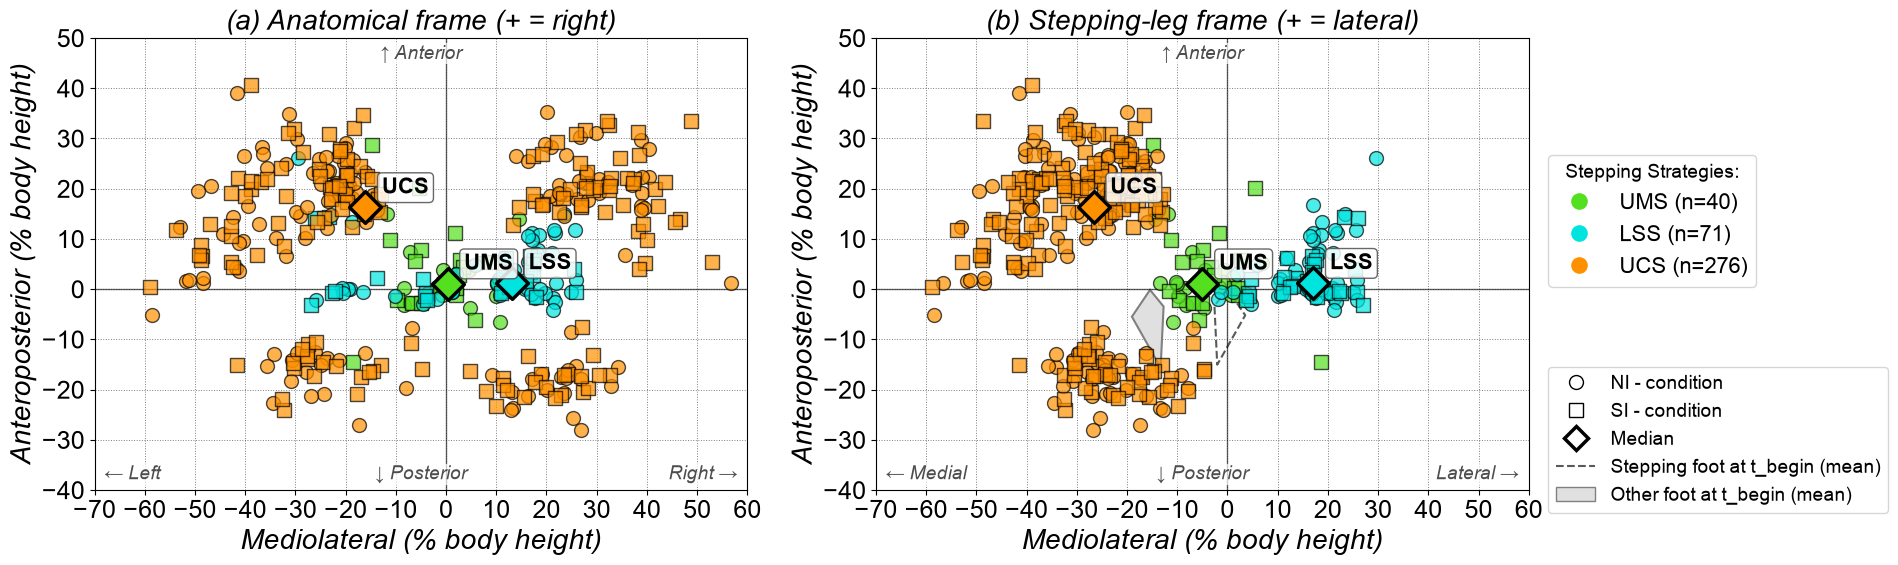

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(2 * style.FIG_WIDTH + 3, 1.25 * style.FIG_HEIGHT))
# Same limits in both panels: same scale and aligned panels
xlim = style.symmetric_limits(np.r_[sel["ml_pct"], sel["ml_lateral_pct"]], step=10)
ylim = style.symmetric_limits(sel["ap_pct"], step=10)
figures.plot_decomposition(axes[0], sel, frame="anatomical", xlim=xlim, ylim=ylim, show_feet=False)
figures.plot_decomposition(axes[1], sel, frame="lateral", xlim=xlim, ylim=ylim)
style.set_labels(axes[0], title="(a) Anatomical frame (+ = right)")
style.set_labels(axes[1], title="(b) Stepping-leg frame (+ = lateral)")
figures.decomposition_legends(axes[1], sel)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "Fig_FirstStep_Decomposition_ML_AP.pdf", bbox_inches="tight")
plt.show()

## 6. Figure 2: distribution of each component per strategy

Box plots (median, interquartile range, whiskers at 1.5 IQR) with all trials overlaid. ML is shown in the stepping-leg frame.

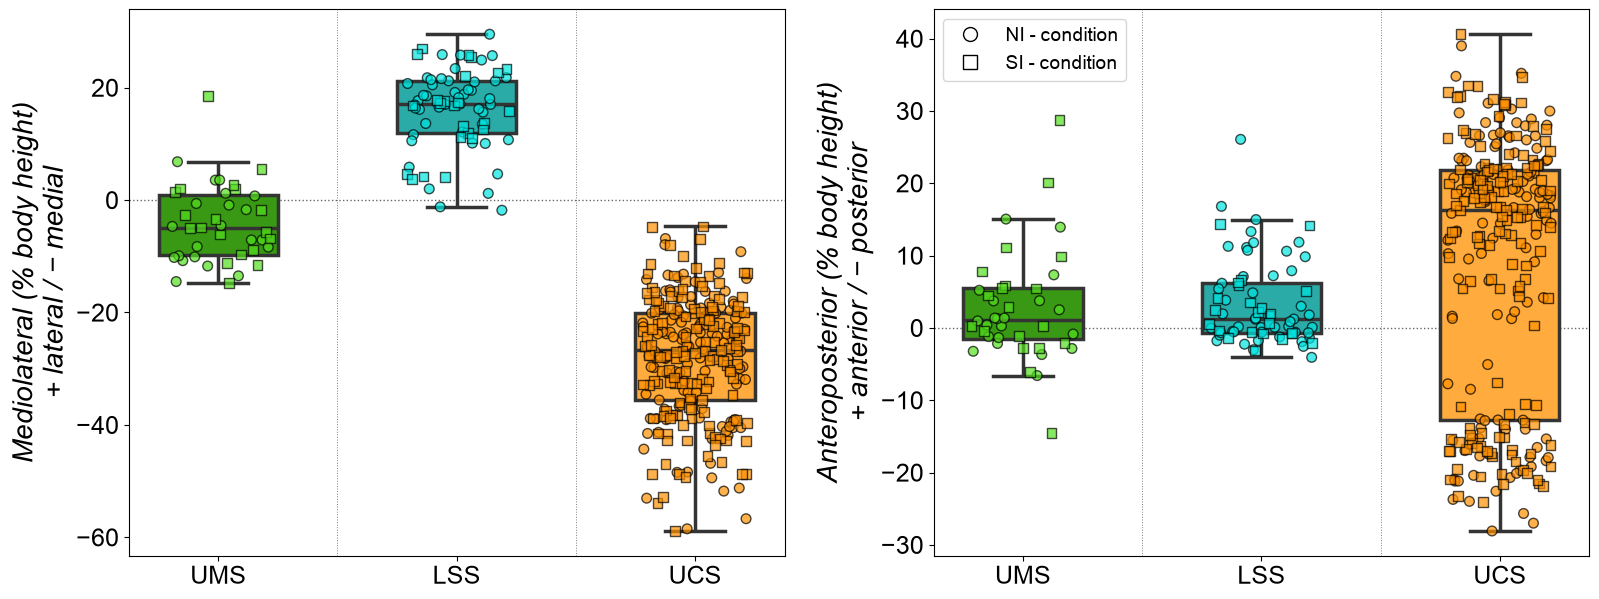

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(2 * style.FIG_WIDTH, style.FIG_HEIGHT))
figures.plot_component_boxes(axes[0], sel, "ml_lateral_pct", "Mediolateral (% body height)\n+ lateral / − medial")
figures.plot_component_boxes(axes[1], sel, "ap_pct", "Anteroposterior (% body height)\n+ anterior / − posterior")
handles, labels = style.condition_handles()
axes[1].legend(handles, labels, fontsize=style.FONT_SIZE - 6, loc="upper left")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "Fig_FirstStep_Components_Boxplots.pdf", bbox_inches="tight")
plt.show()

## 7. Descriptive statistics

In [7]:
def summarise(df, columns, by="strategy", order=style.STRATEGY_ORDER):
    """Median [Q1, Q3] and mean (SD) of columns per group.

    Parameters
    ----------
    df : pandas.DataFrame
        Selected first-step rows.
    columns : dict of str -> str
        {column name: display name}.
    by : str or list of str, optional
        Grouping column(s). Default "strategy".
    order : list, optional
        Order of the first grouping level.

    Returns
    -------
    pandas.DataFrame
        One row per group: n, then "median [Q1, Q3]" and "mean (SD)" for each
        column (values in the unit of the column, here % body height).
    """
    rows = {}
    for key, g in df.groupby(by):
        row = {"n": len(g)}
        for col, name in columns.items():
            q1, med, q3 = g[col].quantile([0.25, 0.5, 0.75])
            row[f"{name} median [Q1, Q3]"] = f"{med:.1f} [{q1:.1f}, {q3:.1f}]"
            row[f"{name} mean (SD)"] = f"{g[col].mean():.1f} ({g[col].std():.1f})"
        rows[key] = row
    out = pd.DataFrame(rows).T
    if isinstance(by, str):
        out = out.loc[[s for s in order if s in out.index]]
    return out


sel["step_length_pct"] = np.hypot(sel["ml_pct"], sel["ap_pct"])
columns = {"ml_lateral_pct": "ML lateral", "ap_pct": "AP", "step_length_pct": "Length"}
summarise(sel, columns)

,n,"ML lateral median [Q1, Q3]",ML lateral mean (SD),"AP median [Q1, Q3]",AP mean (SD),"Length median [Q1, Q3]",Length mean (SD)
UMS,40,"-5.0 [-9.7, 0.8]",-4.2 (6.9),"1.1 [-1.5, 5.5]",2.7 (7.6),"8.3 [4.1, 10.7]",9.2 (6.6)
LSS,71,"17.1 [12.0, 21.2]",16.2 (7.1),"1.2 [-0.7, 6.2]",3.4 (5.8),"18.1 [12.8, 22.0]",17.3 (7.6)
UCS,276,"-26.6 [-35.6, -20.1]",-28.0 (10.7),"16.3 [-12.7, 21.9]",8.9 (17.9),"33.8 [28.4, 41.7]",34.9 (9.0)


Same statistics per sensory condition:

In [8]:
summarise(sel, columns, by=["strategy", "condition"]).reindex(
    [(s, c) for s in style.STRATEGY_ORDER for c in config.CONDITIONS])

n ML lateral median [Q1, Q3] ML lateral mean (SD)  \
UMS NI   21         -7.1 [-10.1, -0.6]           -5.2 (6.1)   
    SI   19           -4.9 [-7.9, 1.7]           -3.2 (7.6)   
LSS NI   47          17.7 [12.8, 21.1]           16.3 (7.2)   
    SI   24          16.8 [11.7, 22.3]           15.9 (7.2)   
UCS NI  133       -25.8 [-34.5, -20.6]         -28.0 (10.4)   
    SI  143       -27.2 [-36.4, -19.7]         -28.1 (11.1)   

        AP median [Q1, Q3] AP mean (SD) Length median [Q1, Q3]  \
UMS NI     1.0 [-1.3, 3.7]    1.7 (5.3)        8.4 [3.8, 10.2]   
    SI     2.8 [-1.6, 6.8]    3.8 (9.5)        8.3 [5.7, 11.4]   
LSS NI     1.2 [-0.6, 7.5]    3.8 (6.4)      19.5 [13.4, 21.8]   
    SI     1.9 [-0.7, 4.3]    2.5 (4.5)      17.3 [12.3, 22.3]   
UCS NI  17.5 [-12.6, 21.9]   9.2 (18.1)      33.3 [29.1, 41.3]   
    SI  15.4 [-13.2, 21.7]   8.6 (17.9)      34.1 [28.0, 42.2]   

       Length mean (SD)  
UMS NI        8.1 (5.3)  
    SI       10.3 (7.9)  
LSS NI       17.7 (7.6)  
    SI       16.6 (7.6)  
UCS NI       35.0 (8.6)  
    SI       34.8 (9.4)

Share of steps per landing quadrant: lateral (ML lateral > 0) vs medial, and anterior (AP > 0) vs posterior. Values in %.

In [9]:
quadrant = pd.DataFrame({
    "lateral (%)": sel.groupby("strategy")["ml_lateral_pct"].apply(lambda v: 100 * (v > 0).mean()),
    "anterior (%)": sel.groupby("strategy")["ap_pct"].apply(lambda v: 100 * (v > 0).mean()),
    "n": sel.groupby("strategy").size(),
}).loc[style.STRATEGY_ORDER]
quadrant

,lateral (%),anterior (%),n
strategy,,,
UMS,27.5,62.5,40
LSS,97.2,63.4,71
UCS,0.0,71.4,276


## 8. Observations (this run)

- **LSS.** The loaded foot steps outward: ML lateral median ≈ +17 % body height. The AP component stays small (median ≈ +1 %), so LSS is an almost purely sideways step.
- **UMS.** The unloaded foot mostly moves medially towards the other foot: ML lateral median ≈ −5 %, medial in about 72 % of the trials, with a small AP component. Medial end positions sit between the origin and the initial position of the other foot (panel b). This matches the definition: no crossing, so the foot cannot pass the other foot. The remaining ~28 % land slightly lateral (mostly < +7 %). These UMS are named by the CoM path (it entered the other foot first), not by the foot direction.
- **UCS.** The foot travels medially past the other foot (median ≈ −27 %). The AP component is **bimodal**: about 71 % of the crossovers go in front of the stance leg (AP ≈ +15 to +30 %) and 29 % behind it (AP ≈ −10 to −25 %). Summary statistics of AP for UCS (mean, median) therefore hide two distinct behaviours.
- In the anatomical frame (panel a) the clusters are mirrored left/right according to the stepping foot. The stepping-leg frame (panel b) pools both sides.

## 9. Limitations

- **Lab axes as ML/AP axes.** The participant's heading at perturbation onset differs from the lab axes by at most 8.5° (feet) in this dataset. The resulting error on the components is small compared with the spread within each strategy (`02_Analysis_Test.ipynb`, section 5).
- **Open data vs the files used before.** In 26 trials the open data contain an earlier, longer version of the recording than the files used in the previous analysis. For the strategies studied here, only one UCS trial is affected (S15 SI PM0_2, detected as a leg abduction in the open data).
- **Small UMS sample.** UMS is the rarest lateral strategy (n = 40). Its statistics are less precise than those of LSS and UCS.
- **Pooling sides.** The stepping-leg frame pools left-foot and right-foot steps, which assumes left/right symmetry. Panel (a) keeps them separate.